In [6]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score, 
    roc_curve, 
    auc
)
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# 1. DATA LOADING
train_df = pd.read_csv(r"C:\Users\josep\Data analysis\Telecom churn data\churn-bigml-80.csv")
test_df = pd.read_csv(r"C:\Users\josep\Data analysis\Telecom churn data\churn-bigml-20.csv")

# 2. PREPROCESSING & FEATURE ENGINEERING
def preprocess_telecom_data(df):
    data = df.copy()
    
    # Binary Encodings
    data['Churn'] = data['Churn'].astype(int)
    data['International plan'] = data['International plan'].map({'Yes': 1, 'No': 0})
    data['Voice mail plan'] = data['Voice mail plan'].map({'Yes': 1, 'No': 0})
    
    # Feature Engineering: Aggregates & Risk Thresholds
    data['Total charge'] = (
        data['Total day charge'] + data['Total eve charge'] + 
        data['Total night charge'] + data['Total intl charge']
    )
    data['Total minutes'] = (
        data['Total day minutes'] + data['Total eve minutes'] + 
        data['Total night minutes'] + data['Total intl minutes']
    )
    data['Total calls'] = (
        data['Total day calls'] + data['Total eve calls'] + 
        data['Total night calls'] + data['Total intl calls']
    )
    data['CS_Calls_HighRisk'] = (data['Customer service calls'] >= 4).astype(int)
    
    return data

train_clean = preprocess_telecom_data(train_df)
test_clean = preprocess_telecom_data(test_df)

In [3]:
# 3. EXPLICIT FEATURE SELECTION
# Excludes administrative IDs ('State', 'Area code') and low-signal features ('Account length', call counts)
SELECTED_FEATURES = [
    'Total charge',
    'International plan',
    'Customer service calls',
    'CS_Calls_HighRisk',
    'Total day minutes',
    'Total day charge',
    'Total minutes',
    'Total intl calls',
    'Total intl minutes',
    'Total intl charge',
    'Number vmail messages',
    'Voice mail plan'
]

X_train = train_clean[SELECTED_FEATURES]
y_train = train_clean['Churn']

X_test = test_clean[SELECTED_FEATURES]
y_test = test_clean['Churn']

print(f"Features selected for modeling ({len(SELECTED_FEATURES)}):")
print(SELECTED_FEATURES)

Features selected for modeling (12):
['Total charge', 'International plan', 'Customer service calls', 'CS_Calls_HighRisk', 'Total day minutes', 'Total day charge', 'Total minutes', 'Total intl calls', 'Total intl minutes', 'Total intl charge', 'Number vmail messages', 'Voice mail plan']


In [4]:
# 4. MODEL TRAINING
rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=10,
    class_weight='balanced',
    random_state=42
)
rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=10, n_estimators=150,
                       random_state=42)

In [5]:
# 5. MODEL EVALUATION
y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

print("\n=== EVALUATION ON SELECTED FEATURES ===")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Test ROC-AUC:  {roc_auc_score(y_test, y_prob):.4f}\n")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


=== EVALUATION ON SELECTED FEATURES ===
Test Accuracy: 0.9820
Test ROC-AUC:  0.9192

Confusion Matrix:
 [[572   0]
 [ 12  83]]

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99       572
           1       1.00      0.87      0.93        95

    accuracy                           0.98       667
   macro avg       0.99      0.94      0.96       667
weighted avg       0.98      0.98      0.98       667



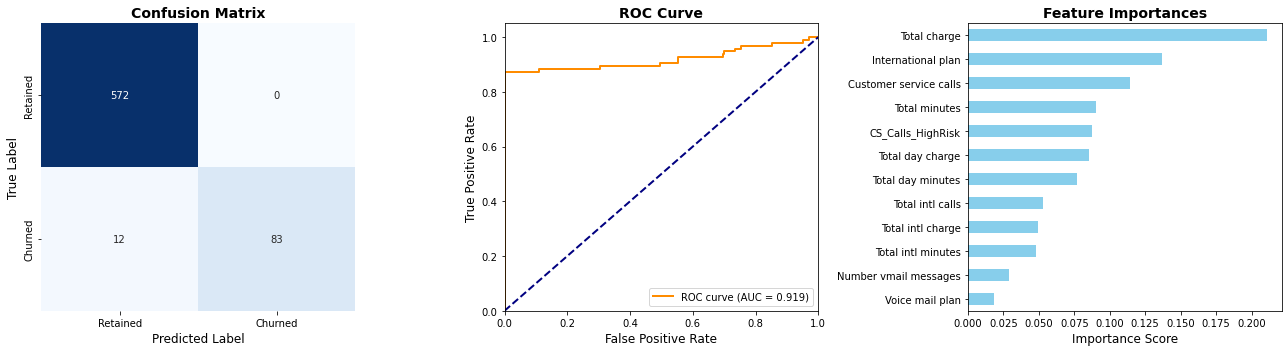

In [8]:
# Set figure layout for standard notebook display
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix Plot
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Retained', 'Churned'], yticklabels=['Retained', 'Churned'])
axes[0].set_title('Confusion Matrix', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontsize=12)
axes[0].set_ylabel('True Label', fontsize=12)

# 2. ROC Curve Plot
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate', fontsize=12)
axes[1].set_ylabel('True Positive Rate', fontsize=12)
axes[1].set_title('ROC Curve', fontsize=14, fontweight='bold')
axes[1].legend(loc="lower right")


# 3. Feature Importance Plot
importances = pd.Series(rf.feature_importances_, index=SELECTED_FEATURES).sort_values(ascending=True)
importances.plot(kind='barh', color='skyblue', ax=axes[2])
axes[2].set_title('Feature Importances', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Importance Score', fontsize=12)

plt.tight_layout()
plt.show()